# Calibration 4 — Khử nhân tố phi tuyến bằng autoencoder (bảng 60 mã)

Calibration 02 kết luận: phải khử nhân tố chung trước EASE, và mọi cách khử đã thử đều **tuyến tính** (hệ số tải $\beta_i$ cố định).
Hướng phát triển ở đây theo hai bài báo:

- **Gu, Kelly & Xiu (2021)**, *Autoencoder asset pricing models*, J. Econometrics 222, 429–450 (doi:10.1016/j.jeconom.2020.07.009):
  nhân tố là **danh mục tuyến tính** của lợi suất (mạng nhân tố một lớp, pt. 13–15), hệ số tải là hàm phi tuyến; autoencoder tuyến tính
  một lớp ẩn trùng PCA (Mệnh đề 1); huấn luyện bằng Adam + L1 + dừng sớm + trung bình nhiều seed; đánh giá bằng $R^2$ tổng ngoài mẫu (pt. 20).
- **Spilak & Härdle (2022)**, *Does non-linear factorization of financial returns help build better and stabler portfolios?* (arXiv:2204.02757):
  $x_t = W\,\mathrm{ReLU}(H^\top x_t + b_E) + b_D + \varepsilon_t$ với ràng buộc $H, W \ge 0$, phạt L1, trực giao mềm, phạt tương quan nhân tố;
  kết luận **autoencoder không hơn mô hình tuyến tính** về sai số tái tạo, và vùng ReLU tắt (đuôi trái) **không được giải thích**.

**Mô hình so sánh** (`src/nonlinear_factor.py`), cùng nhân tố $f_t = H^\top x_t + b_E$:

| Ký hiệu | Phần giải mã | Ghi chú |
|---|---|---|
| `pca` | $\hat x = L L^\top x_s$ | đối chứng tuyến tính |
| `linear` | $\hat x = W f + b_D$ | ≡ PCA (Gu và cs., Mệnh đề 1) — kiểm tra cài đặt |
| `relu` | $\hat x = W\,\mathrm{ReLU}(f) + b_D$ | Spilak & Härdle (2022) |
| `nonlinear` | $\hat x = W f + V\,\mathrm{ReLU}(A f + c) + b_D$ | **đề xuất**: hệ số tải phụ thuộc trạng thái thị trường; chứa `linear` khi $V = 0$ |

**Hai thay đổi so với Calibration 02:**
1. Mẫu là **60 mã** (20 mã giai đoạn trước + 40 mã HOSE bổ sung, `src/download_extended.py`) — nhân tố ước lượng từ nhiều mã nên ít lẫn nhiễu riêng của từng mã.
2. Phần dư tính **ngoài mẫu bằng cross-fitting** 5 khối thời gian: mô hình linh hoạt không được "học thuộc" cú sốc riêng của chính phiên cần khử.

**Câu hỏi:** khử phi tuyến có làm phần dư **sạch hơn ở đuôi** (ít "đồng sập" với thị trường hơn) và EASE ít thứ tự giả hơn không?

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed
import eda_utils as U
import causal_tail as CT
import tail_preprocessing as TP
import validation as V
import calibration as C
import nonlinear_factor as NF

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 80)
SYMBOLS, PAL, SECTOR = U.SYMBOLS, U.PALETTE, U.SECTOR
FOLDER = "calibration"
RECOMPUTE = False          # True: chạy lại mô phỏng và lưới mô hình (≈ 10 phút); False: đọc bảng đã lưu nếu có
TAB = ROOT / "report" / "table" / FOLDER
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)
NU_CAL = 0.35                                       # ν chọn ở Calibration 01
ARCH_COLORS = {"pca": PAL["red_strong"], "linear": PAL["red_2"], "relu": PAL["neutral"], "nonlinear": PAL["blue_main"]}

def cached(name, fn):
    path = TAB / f"{name}.csv"
    if path.exists() and not RECOMPUTE:
        return pd.read_csv(path, encoding="utf-8-sig", index_col=0)
    df = fn()
    U.save_table(df, name, FOLDER)
    return df

## 1. Dữ liệu: 60 mã HOSE

**Tiêu chí chọn 40 mã bổ sung** (`download_extended.select_universe`, không chọn tay): từ 90 ứng viên đang niêm yết HOSE, giữ mã (i) có dữ liệu trước 01/06/2018 và thiếu ≤ 2% phiên,
(ii) lịch sử giống HOSE: ≤ 2 phiên $|r| > 7{,}5\%$ (20 mã giai đoạn trước: 0 phiên) — loại mã chuyển từ HNX/UPCoM trong cửa sổ, (iii) lấy 40 mã có giá trị giao dịch
trung vị 2 năm cuối cao nhất. Phần dư GARCH(1,1)-t lấy từ Processing 02 (2.103 phiên chung).

In [2]:
uni = pd.read_csv(ROOT / "data" / "reference" / "extended_universe.csv")
EXT = uni.loc[uni["selected"], "symbol"].tolist()
ALL = SYMBOLS                                     # 60 mã = 20 mã giai đoạn trước + 40 mã bổ sung (symbol_meta.csv)
assert set(EXT) | set(U.BASE_SYMBOLS) == set(ALL)
Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid.parquet")[ALL]     # phần dư GARCH-t (Processing 02)
n = len(Z); KC = CT.default_k(n, NU_CAL)
print(f"Bảng 60 mã: n = {n} phiên ({Z.index[0]:%d/%m/%Y} → {Z.index[-1]:%d/%m/%Y}), k = {KC}")

def reason_group(r):
    if r.startswith("đã trong"): return "Mã nghiên cứu"
    if "sau" in r: return "Niêm yết sau 06/2018"
    if "HOSE" in r: return "Lịch sử ngoài HOSE"
    if "top n" in r: return "Thanh khoản thấp"
    if "thiếu" in r: return "Thiếu phiên"
    return "Lỗi tải"
excl = uni.loc[~uni["selected"], "reason"].map(reason_group).value_counts()
sec_ext = pd.Series({s: SECTOR[s] for s in EXT}).value_counts().sort_values()
excl, sec_ext

Bảng 60 mã: n = 2103 phiên (05/06/2018 → 25/11/2026), k = 14


(reason
 Thanh khoản thấp        27
 Lịch sử ngoài HOSE      15
 Niêm yết sau 06/2018     8
 Name: count, dtype: int64,
 Nông nghiệp      1
 Thép             2
 Hoá chất         3
 Ngân hàng        3
 Chứng khoán      4
 Công nghiệp      5
 Tiêu dùng        6
 Năng lượng       6
 Bất động sản    10
 Name: count, dtype: int64)

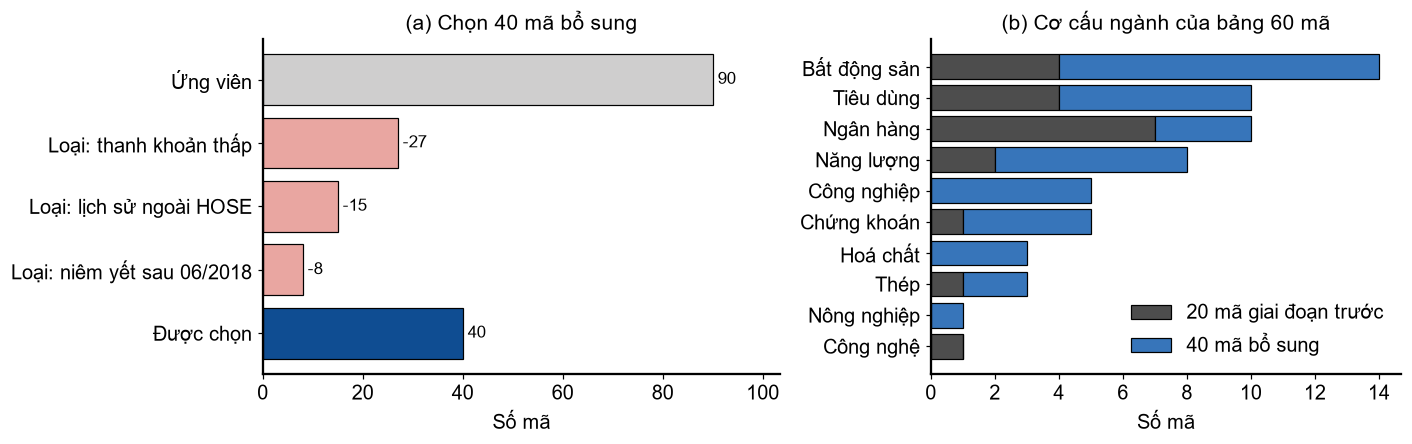

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
labels = ["Ứng viên", *[f"Loại: {k[0].lower() + k[1:]}" for k in excl.index], "Được chọn"]
vals = [len(uni), *(-excl.values), int(uni["selected"].sum())]
cols = [PAL["neutral"], *[PAL["red_2"]] * len(excl), PAL["blue_main"]]
y = np.arange(len(labels))[::-1]
ax.barh(y, np.abs(vals), color=cols, edgecolor="black", linewidth=0.8)
for yi, v in zip(y, vals):
    ax.text(abs(v) + 1, yi, f"{v:+d}" if v < 0 else str(v), va="center", fontsize=11)
ax.set_yticks(y, labels); ax.set_xlabel("Số mã"); ax.set_title("(a) Chọn 40 mã bổ sung")
ax.set_xlim(0, len(uni) * 1.15)
ax = axes[1]
sec20 = pd.Series({s: SECTOR[s] for s in U.BASE_SYMBOLS}).value_counts()
secs = sorted(set(sec20.index) | set(sec_ext.index), key=lambda s: -(sec20.get(s, 0) + sec_ext.get(s, 0)))
yy = np.arange(len(secs))[::-1]
ax.barh(yy, [sec20.get(s, 0) for s in secs], color=PAL["gray_dark"], label="20 mã giai đoạn trước", edgecolor="black", linewidth=0.8)
ax.barh(yy, [sec_ext.get(s, 0) for s in secs], left=[sec20.get(s, 0) for s in secs], color=PAL["blue_secondary"],
        label="40 mã bổ sung", edgecolor="black", linewidth=0.8)
ax.set_yticks(yy, secs); ax.set_xlabel("Số mã"); ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.set_title("(b) Cơ cấu ngành của bảng 60 mã"); ax.legend(loc="lower right")
U.finalize_figure(fig, "04_extended_universe", folder=FOLDER); plt.show()

## 2. Có phi tuyến không? Hệ số tải khi thị trường tăng và giảm

**Tính gì:** với mỗi mã, hồi quy $z_{i,t} = a_i + \beta_i^{+} m_t^{+} + \beta_i^{-} m_t^{-} + e_{i,t}$, $m^{+} = \max(m, 0)$, $m^{-} = \min(m, 0)$,
$m$ = trung bình đều 59 mã còn lại (Ang, Chen & Xing 2006); kiểm định $D_i = \beta_i^- - \beta_i^+ = 0$ bằng sai số chuẩn HC0.

**Vì sao quan trọng:** nếu mọi mã có **cùng tỷ lệ** $\beta^-/\beta^+$, phần chung là $g(F)$ giống nhau cho mọi mã và nhân tố tuyến tính $f \propto g(F)$ đã khử đúng
(kiểm thử `test_homogeneous_asymmetry_is_absorbed_by_linear_factor`). Phi tuyến chỉ có ích khi độ bất đối xứng **khác nhau giữa các mã**.

Số mã |t(D)| > 2: 17/60 (kỳ vọng ≈ 2.7 nếu β⁺ = β⁻ ở mọi mã); D > 0: 12, D < 0: 5; độ lệch chuẩn của D giữa các mã = 0.166


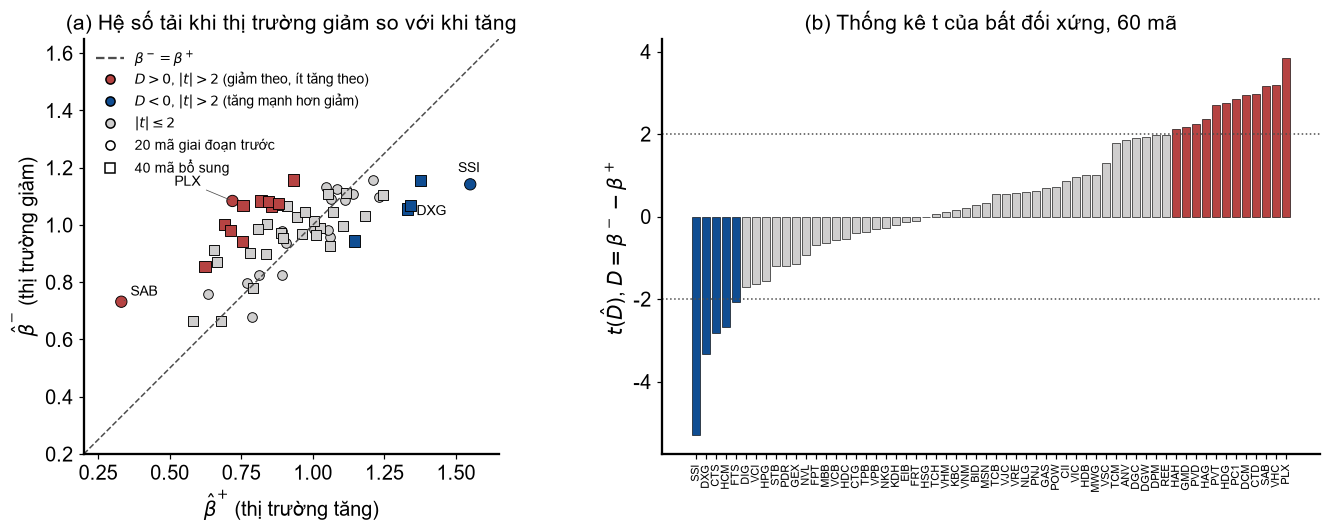

,beta_up,beta_down,D,t_D,nhom
SSI,1.550,1.142,-0.408,-5.299,20 cũ
DXG,1.330,1.056,-0.274,-3.333,bổ sung
CTS,1.341,1.068,-0.273,-2.824,bổ sung
HCM,1.375,1.156,-0.219,-2.687,bổ sung
FTS,1.145,0.944,-0.201,-2.079,bổ sung
HAH,0.755,0.941,0.186,2.121,bổ sung
GMD,0.881,1.076,0.195,2.164,bổ sung
PVD,0.856,1.066,0.210,2.241,bổ sung
HAG,0.623,0.856,0.233,2.357,bổ sung
PVT,0.819,1.083,0.264,2.702,bổ sung


In [4]:
ud = NF.up_down_betas(Z)
ud["nhom"] = ["20 cũ" if s in U.BASE_SYMBOLS else "bổ sung" for s in ud.index]
U.save_table(ud, "04_up_down_betas", FOLDER)
sig = ud["t_D"].abs() > 2
print(f"Số mã |t(D)| > 2: {sig.sum()}/60 (kỳ vọng ≈ {0.0455 * 60:.1f} nếu β⁺ = β⁻ ở mọi mã); "
      f"D > 0: {(sig & (ud.t_D > 0)).sum()}, D < 0: {(sig & (ud.t_D < 0)).sum()}; độ lệch chuẩn của D giữa các mã = {ud.D.std():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
lim = [0.2, 1.65]
ax.plot(lim, lim, color=PAL["gray_dark"], ls="--", lw=1, label=r"$\beta^- = \beta^+$")
for grp, mk in [("20 cũ", "o"), ("bổ sung", "s")]:
    d = ud[ud.nhom == grp]
    s_ = d["t_D"].abs() > 2
    ax.scatter(d.loc[~s_, "beta_up"], d.loc[~s_, "beta_down"], marker=mk, s=40, color=PAL["neutral"], edgecolor="black", lw=0.6)
    ax.scatter(d.loc[s_, "beta_up"], d.loc[s_, "beta_down"], marker=mk, s=55,
               color=np.where(d.loc[s_, "D"] > 0, PAL["red_strong"], PAL["blue_main"]), edgecolor="black", lw=0.6)
LABELS = {"SSI": (-8, 8), "DXG": (6, -4), "SAB": (6, 4), "PLX": (-38, 10)}   # 4 mã tiêu biểu, vị trí nhãn tránh chồng
for s, off in LABELS.items():
    ax.annotate(s, (ud.loc[s, "beta_up"], ud.loc[s, "beta_down"]), xytext=off, textcoords="offset points", fontsize=9,
                arrowprops=dict(arrowstyle="-", lw=0.5, color=PAL["gray_dark"]))
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel(r"$\hat\beta^{+}$ (thị trường tăng)"); ax.set_ylabel(r"$\hat\beta^{-}$ (thị trường giảm)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=PAL["gray_dark"], ls="--", label=r"$\beta^- = \beta^+$"),
                   Line2D([], [], marker="o", ls="", color=PAL["red_strong"], mec="black", label=r"$D>0$, $|t|>2$ (giảm theo, ít tăng theo)"),
                   Line2D([], [], marker="o", ls="", color=PAL["blue_main"], mec="black", label=r"$D<0$, $|t|>2$ (tăng mạnh hơn giảm)"),
                   Line2D([], [], marker="o", ls="", color=PAL["neutral"], mec="black", label=r"$|t| \leq 2$"),
                   Line2D([], [], marker="o", ls="", color="white", mec="black", label="20 mã giai đoạn trước"),
                   Line2D([], [], marker="s", ls="", color="white", mec="black", label="40 mã bổ sung")],
          fontsize=9, loc="upper left")
ax.set_title("(a) Hệ số tải khi thị trường giảm so với khi tăng")
ax = axes[1]
o = ud.sort_values("t_D")
ax.bar(np.arange(len(o)), o["t_D"], color=[PAL["red_strong"] if v > 2 else PAL["blue_main"] if v < -2 else PAL["neutral"] for v in o["t_D"]],
       edgecolor="black", linewidth=0.4)
ax.axhline(2, color=PAL["gray_dark"], ls=":", lw=1); ax.axhline(-2, color=PAL["gray_dark"], ls=":", lw=1)
ax.set_xticks(np.arange(len(o)), o.index, rotation=90, fontsize=7)
ax.set_ylabel(r"$t(\hat D)$, $D = \beta^- - \beta^+$"); ax.set_title("(b) Thống kê t của bất đối xứng, 60 mã")
U.finalize_figure(fig, "04_up_down_betas", folder=FOLDER); plt.show()
ud.loc[sig].sort_values("t_D").round(3)

### Phân tích

- **Bất đối xứng có thật và khác nhau giữa các mã:** 17/60 mã có $|t(\hat D)| > 2$, so với ≈ 2,7 mã nếu $\beta^+ = \beta^-$ ở mọi mã; độ lệch chuẩn của $\hat D$ giữa các mã là 0,17.
  Đây đúng là dạng phi tuyến mà một hệ số tải cố định không hấp thụ được (mục 0: bất đối xứng đồng nhất thì nhân tố tuyến tính đã khử đúng).
- **$D < 0$ (5 mã): cả nhóm chứng khoán và DXG** — SSI ($\hat\beta^+$ = 1,55 so với $\hat\beta^-$ = 1,14, $t$ = −5,3), DXG, CTS, HCM, FTS: tăng mạnh hơn hẳn khi thị trường lên.
- **$D > 0$ (12 mã): nhóm phòng thủ, dầu khí, cảng biển** — PLX, VHC, SAB, CTD, DCM, PC1, HDG, PVT, HAG, PVD, GMD, HAH: ít tham gia nhịp tăng nhưng vẫn giảm theo khi thị trường sập (SAB: 0,33 so với 0,73).
- Trong 20 mã giai đoạn trước chỉ SSI, PLX, SAB bất đối xứng rõ; 14/17 mã bất đối xứng thuộc nhóm bổ sung.

## 3. Mô phỏng: khi nào khử phi tuyến có ích cho EASE?

**Thiết kế:** 60 mã, $n$ = 2.103, $x_i = \beta_i^{+}\max(F,0) + \beta_i^{-}\min(F,0) + u_i$, $F, \varepsilon \sim t_\nu$ ($\nu$ = trung bình GARCH),
`NF.simulate_asymmetric_factor_scm`. Tải trung bình $\lambda_i$ = tải một nhân tố của dữ liệu thật; độ bất đối xứng $d_i = (\hat\beta^-_i - \hat\beta^+_i)/(\hat\beta^-_i + \hat\beta^+_i)$
lấy từ mục 2, nhân hệ số $a$: $\beta_i^{\pm} = \lambda_i(1 \mp a\,d_i)$. Ba kịch bản: $a = 0$ (tuyến tính), $a = 1$ (khớp dữ liệu thật), $a = 3$ (bất đối xứng mạnh).
$H_0$: không cạnh; $H_1$: DAG thưa giữa 60 mã (xác suất cạnh $0{,}08\cdot19/59$ ≈ 1,5 cạnh/mã, hệ số $U(0{,}2;0{,}5)$). EASE chạy trên 60 mã, $k$ = 14.

**Phương pháp:** gốc; PCA $K$ = 1, 2 và AE phi tuyến $K$ = 1 (cross-fitting 5 khối); hệ số có điều kiện thị trường (Calibration 02).

**Thước đo:** dưới $H_0$ — $\overline{\hat\Psi}$ (lý tưởng 0,5); Spearman(vị trí EASE, $d_i$) — thứ tự giả theo bất đối xứng (lý tưởng 0);
**độ lệch đuôi có hướng** $\delta = \tfrac12\big(|\hat\Gamma^-_{m\to e_i} - \tfrac12| + |\hat\Gamma^+_{m\to e_i} - \tfrac12|\big)$ trung bình 60 mã, $m$ = trung bình đều 60 mã
(phần dư không còn đồng sập/đồng tăng với thị trường ⇔ $\delta \approx 0$). Dưới $H_1$ — SID.

In [5]:
lam60 = V.fit_one_factor(Z).to_numpy()
d60 = ((ud["beta_down"] - ud["beta_up"]) / (ud["beta_down"] + ud["beta_up"])).reindex(ALL).to_numpy()
gp20 = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_garch_params.csv", index_col=0, encoding="utf-8-sig")
NU = float(gp20["nu"].mean())
SCEN = {"tuyến tính (a=0)": 0.0, "khớp thật (a=1)": 1.0, "bất đối xứng mạnh (a=3)": 3.0}
SIM_METHODS = ["raw", "pca1", "pca2", "nl1", "conditional"]
SIM_LABELS = {"raw": "Gốc", "pca1": "PCA K=1 (60 mã)", "pca2": "PCA K=2 (60 mã)", "nl1": "AE phi tuyến K=1 (60 mã)",
              "conditional": "Có điều kiện thị trường"}
SIM_COLORS = {"raw": PAL["gray_dark"], "pca1": PAL["red_strong"], "pca2": PAL["red_2"], "nl1": PAL["blue_main"], "conditional": PAL["teal"]}

def tail_dev(m, E):
    # δ: trung bình |Γ⁻ − ½| và |Γ⁺ − ½| của (thị trường → phần dư) trên các cột của E
    out = []
    for c in range(E.shape[1]):
        gl = CT.gamma_lower_coef(m, E[:, c], KC); gu = CT.gamma_coef(m, E[:, c], KC)
        out.append(0.5 * (abs(gl - 0.5) + abs(gu - 0.5)))
    return float(np.mean(out))

def betas(a):
    bu = np.clip(lam60 * (1 - a * d60), 0.02, 0.95); bd = np.clip(lam60 * (1 + a * d60), 0.02, 0.95)
    return bu, bd

def sim_one(child, scen, h1):
    rng = np.random.default_rng(child)
    bu, bd = betas(SCEN[scen])
    A20 = CT.random_dag(P, rng, edge_prob=0.08 * 19 / (P - 1)) if h1 else np.zeros((P, P), int)   # ~1,5 cạnh/mã
    B = A20 * rng.uniform(0.2, 0.5, (P, P))
    X = pd.DataFrame(NF.simulate_asymmetric_factor_scm(n, bu, bd, NU, B_coef=B if h1 else None, rng=rng), columns=ALL)
    m = X.mean(axis=1).to_numpy()
    resid = {"raw": X[SYMBOLS]}
    for key, cfg in [("pca1", NF.AEConfig(K=1, arch="pca")), ("pca2", NF.AEConfig(K=2, arch="pca")),
                     ("nl1", NF.AEConfig(K=1, arch="nonlinear", seed=int(rng.integers(1e6))))]:
        resid[key] = NF.crossfit(X, cfg, n_folds=5)["resid"][SYMBOLS]
    da = d60[:P]
    rows = []
    for meth in SIM_METHODS:
        M = C.adjusted_tail_coef_matrix(X[SYMBOLS], k=KC)["adj"] if meth == "conditional" else CT.tail_coef_matrix(resid[meth], k=KC)
        o = CT.ease(M); pos = [o.index(s) for s in SYMBOLS]
        rows.append({"kich_ban": scen, "gia_thuyet": "H1" if h1 else "H0", "phuong_phap": meth,
                     "psi_TB": float(np.nanmean(M.values[OFF])),
                     "rho_asym": stats.spearmanr(pos, da)[0] if SCEN[scen] > 0 else np.nan,
                     "delta_duoi": tail_dev(m, resid[meth].to_numpy()) if meth != "conditional" else np.nan,
                     "SID": CT.sid(A20, CT.order_to_adjacency([SYMBOLS.index(s) for s in o])) if h1 else np.nan})
    return rows

N_REP = 30
def run_sim():
    jobs = [(sc, h1) for sc in SCEN for h1 in (False, True) for _ in range(N_REP)]
    kids = np.random.SeedSequence(404).spawn(len(jobs))
    rows = Parallel(n_jobs=-1)(delayed(sim_one)(c, sc, h1) for c, (sc, h1) in zip(kids, jobs))
    return pd.DataFrame([r for rr in rows for r in rr])

sim = cached("04_nonlinear_sim", run_sim)
summ = sim.groupby(["kich_ban", "gia_thuyet", "phuong_phap"])[["psi_TB", "rho_asym", "delta_duoi", "SID"]].mean()
summ = summ.unstack("gia_thuyet")
summ = summ[[("psi_TB", "H0"), ("rho_asym", "H0"), ("delta_duoi", "H0"), ("SID", "H1")]]
summ.columns = ["Ψ̄ (H0)", "ρ(vị trí, d) (H0)", "δ đuôi (H0)", "SID (H1)"]
summ = summ.reindex(pd.MultiIndex.from_product([list(SCEN), SIM_METHODS]))
U.save_table(summ, "04_nonlinear_sim_summary", FOLDER)
summ.rename(index=SIM_LABELS, level=1).round(3)

Ψ̄ (H0)  ρ(vị trí, d) (H0)  \
tuyến tính (a=0)        Gốc                         0.636                NaN   
                        PCA K=1 (60 mã)             0.501                NaN   
                        PCA K=2 (60 mã)             0.502                NaN   
                        AE phi tuyến K=1 (60 mã)    0.501                NaN   
                        Có điều kiện thị trường     0.513                NaN   
khớp thật (a=1)         Gốc                         0.643             -0.362   
                        PCA K=1 (60 mã)             0.501             -0.024   
                        PCA K=2 (60 mã)             0.502             -0.009   
                        AE phi tuyến K=1 (60 mã)    0.501             -0.010   
                        Có điều kiện thị trường     0.514             -0.103   
bất đối xứng mạnh (a=3) Gốc                         0.639             -0.462   
                        PCA K=1 (60 mã)             0.502              0.039   
                        PCA K=2 (60 mã)             0.502              0.027   
                        AE phi tuyến K=1 (60 mã)    0.501              0.009   
                        Có điều kiện thị trường     0.514             -0.058   

                                                  δ đuôi (H0)  SID (H1)  
tuyến tính (a=0)        Gốc                             0.446     0.022  
                        PCA K=1 (60 mã)                 0.061     0.011  
                        PCA K=2 (60 mã)                 0.061     0.017  
                        AE phi tuyến K=1 (60 mã)        0.057     0.011  
                        Có điều kiện thị trường           NaN     0.010  
khớp thật (a=1)         Gốc                             0.446     0.027  
                        PCA K=1 (60 mã)                 0.079     0.014  
                        PCA K=2 (60 mã)                 0.078     0.021  
                        AE phi tuyến K=1 (60 mã)        0.056     0.014  
                        Có điều kiện thị trường           NaN     0.013  
bất đối xứng mạnh (a=3) Gốc                             0.440     0.021  
                        PCA K=1 (60 mã)                 0.152     0.013  
                        PCA K=2 (60 mã)                 0.068     0.022  
                        AE phi tuyến K=1 (60 mã)        0.055     0.013  
                        Có điều kiện thị trường           NaN     0.012

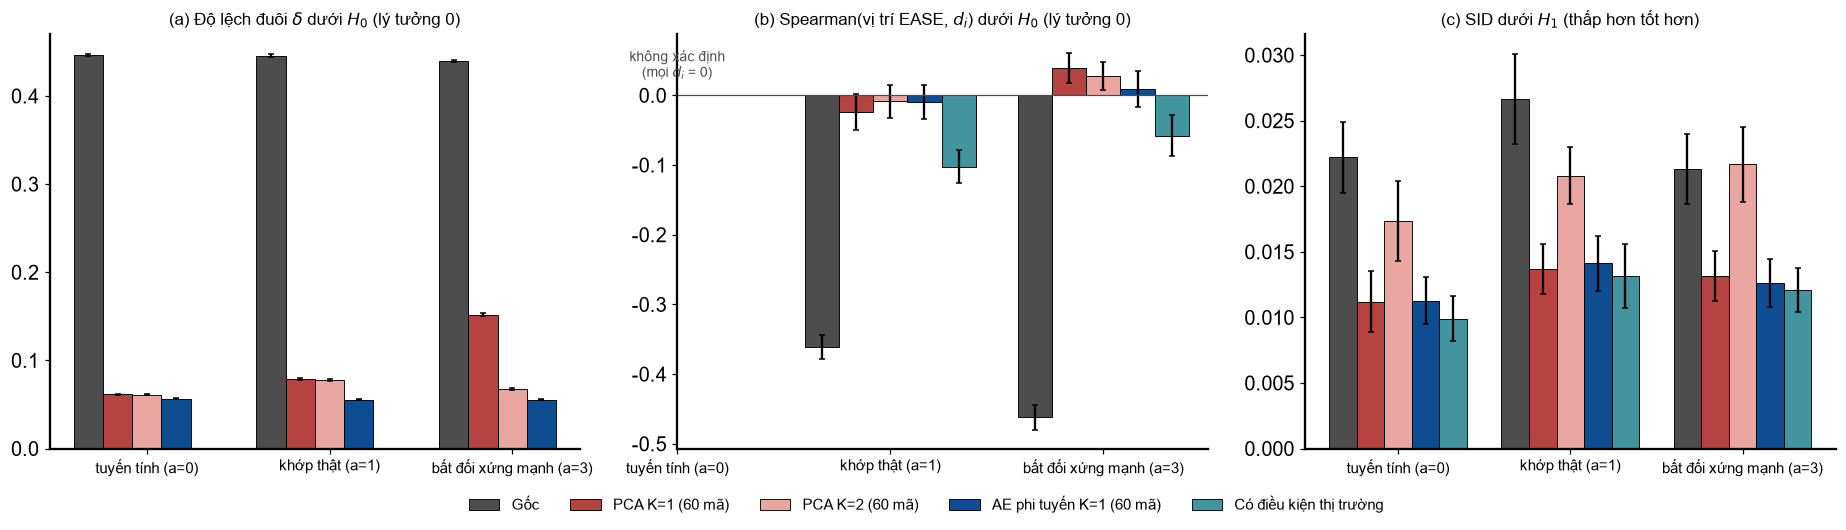

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
w = 0.16; xs = np.arange(len(SCEN))
for ax, (col, h, title, ref) in zip(axes, [("delta_duoi", "H0", r"(a) Độ lệch đuôi $\delta$ dưới $H_0$ (lý tưởng 0)", 0),
                                           ("rho_asym", "H0", r"(b) Spearman(vị trí EASE, $d_i$) dưới $H_0$ (lý tưởng 0)", 0),
                                           ("SID", "H1", r"(c) SID dưới $H_1$ (thấp hơn tốt hơn)", None)]):
    for j, meth in enumerate(SIM_METHODS):
        d = sim[(sim.gia_thuyet == h) & (sim.phuong_phap == meth)].groupby("kich_ban")[col].agg(["mean", "sem"]).reindex(list(SCEN))
        if d["mean"].isna().all():
            continue
        ax.bar(xs + (j - 2) * w, d["mean"], w, yerr=d["sem"], color=SIM_COLORS[meth], edgecolor="black", linewidth=0.6,
               capsize=2, label=SIM_LABELS[meth])
    if ref is not None:
        ax.axhline(ref, color=PAL["gray_dark"], lw=0.8)
    ax.set_xticks(xs, list(SCEN), fontsize=10); ax.set_title(title, fontsize=11)
    if col == "rho_asym":
        ax.text(0, 0.02, "không xác định\n(mọi $d_i$ = 0)", ha="center", va="bottom", fontsize=9, color=PAL["gray_dark"])
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=10, bbox_to_anchor=(0.5, -0.06))
U.finalize_figure(fig, "04_nonlinear_sim", folder=FOLDER); plt.show()

### Phân tích

- **Khi dữ liệu tuyến tính ($a$ = 0), AE phi tuyến không mất gì:** $\delta$ 0,057 so với 0,061 (PCA $K$ = 1), SID 0,011 như PCA.
- **Độ lệch đuôi của PCA tăng theo mức bất đối xứng** (0,061 → 0,079 → 0,152) còn **AE phi tuyến giữ nguyên** (0,056–0,057): phần dư tuyến tính còn thành phần
  $(\beta_i^- - \hat\beta_i)F^-$ đồng sập với thị trường, AE loại được nó.
- PCA $K$ = 2 cũng giảm $\delta$ khi $a$ = 3 dưới $H_0$ (0,068) — vì $\beta^+F^+ + \beta^-F^-$ là mô hình **tuyến tính hai nhân tố** $(F^+, F^-)$ — nhưng có **SID tệ nhất** (0,017–0,022, ngang không khử)
  và dưới $H_1$ lại mất tác dụng ($\delta$ 0,134): nhân tố thứ hai ước lượng từ dữ liệu hấp thụ luôn các cạnh thật. AE phi tuyến dùng **một** nhân tố nên không mắc lỗi này.
- Mọi phương pháp khử đưa $\overline{\hat\Psi}$ về 0,50–0,51 và xoá thứ tự giả theo bất đối xứng (gốc: ρ = −0,36 đến −0,46). Hệ số có điều kiện còn lệch nhẹ (ρ = −0,06 đến −0,10).
- **SID:** AE phi tuyến 0,011–0,014, ngang PCA $K$ = 1 (0,011–0,014) và hệ số có điều kiện (0,010–0,013); chênh lệch trong 1 sai số chuẩn (≈ 0,002).
  Lợi ích của AE là phần dư **sạch đuôi hơn**; ở cấu hình này nó chưa chuyển thành thứ tự EASE tốt hơn rõ rệt.

## 4. Dữ liệu thật: so sánh mô hình theo số nhân tố $K$

**Tính gì:** với mỗi kiến trúc và $K$ = 1–4, cross-fitting 5 khối thời gian, trung bình 3 seed: $R^2$ tổng ngoài mẫu
$R^2 = 1 - \sum (x - \hat x)^2 / \sum x^2$ (Gu và cs. 2021, pt. 20) trên toàn mẫu và trên 5% phiên thị trường giảm/tăng mạnh nhất;
độ lệch đuôi $\delta$ của 60 mã; trên phần dư: $\overline{\hat\Psi}$ và Spearman(vị trí EASE, $\hat\lambda$). Kèm số nhân tố Ahn–Horenstein.

In [7]:
ah = C.n_factors_ahn_horenstein(Z, kmax=6)
print(f"Ahn–Horenstein trên 60 mã: K_ER = {ah['K_ER']}, K_GR = {ah['K_GR']}; μ₁ chiếm {ah['eigen'][0] / ah['eigen'].sum():.0%} phương sai")
lam20 = V.fit_one_factor(Z[SYMBOLS]).to_numpy()
mZ = Z.mean(axis=1).to_numpy()
GRID = [(a, K) for a in ["pca", "linear", "relu", "nonlinear"] for K in [1, 2, 3, 4]]

def grid_one(a, K):
    cf = NF.crossfit(Z, NF.AEConfig(K=K, arch=a, n_ensemble=3, seed=K), n_folds=5)
    rep = NF.fit_report(Z, cf["fitted"])
    E = cf["resid"][SYMBOLS]
    M = CT.tail_coef_matrix(E, k=KC); o = CT.ease(M)
    return {"arch": a, "K": K, **rep, "delta_duoi_20": tail_dev(mZ, E.to_numpy()), "psi_TB_20": float(np.nanmean(M.values[OFF])),
            "rho_lambda": stats.spearmanr([o.index(s) for s in SYMBOLS], lam20)[0], "5_dau": " → ".join(o[:5])}

grid = cached("04_real_grid", lambda: pd.DataFrame(Parallel(n_jobs=-1)(delayed(grid_one)(a, K) for a, K in GRID)))
grid.round(3)

Ahn–Horenstein trên 60 mã: K_ER = 1, K_GR = 1; μ₁ chiếm 35% phương sai


,arch,K,R2,R2_duoi_duoi,R2_duoi_tren,delta_duoi_20,psi_TB_20,rho_lambda,5_dau
0,pca,1,0.342,0.752,0.651,0.094,0.545,0.336,MSN → HAG → FRT → DGC → MWG
1,pca,2,0.377,0.767,0.665,0.093,0.544,0.192,VNM → MSN → VSC → DGC → HAH
2,pca,3,0.411,0.787,0.694,0.076,0.542,0.280,HAH → KDH → HDB → TCH → DGC
3,pca,4,0.439,0.797,0.714,0.077,0.541,0.067,DGC → BID → MSN → HAH → VSC
4,linear,1,0.342,0.752,0.651,0.094,0.545,0.324,MSN → FRT → HAG → CTD → DGC
5,linear,2,0.376,0.767,0.665,0.093,0.544,0.145,VNM → DGC → DGW → MSN → VSC
6,linear,3,0.410,0.786,0.693,0.078,0.541,0.158,DGC → HAH → VHC → KDH → PVT
7,linear,4,0.439,0.796,0.714,0.077,0.541,0.067,DGC → MSN → BID → HAG → HAH
8,relu,1,0.334,0.714,0.651,0.143,0.564,0.391,FRT → DXG → MSN → TCM → POW
9,relu,2,0.375,0.765,0.659,0.104,0.546,0.322,DGC → MWG → DGW → MSN → DXG


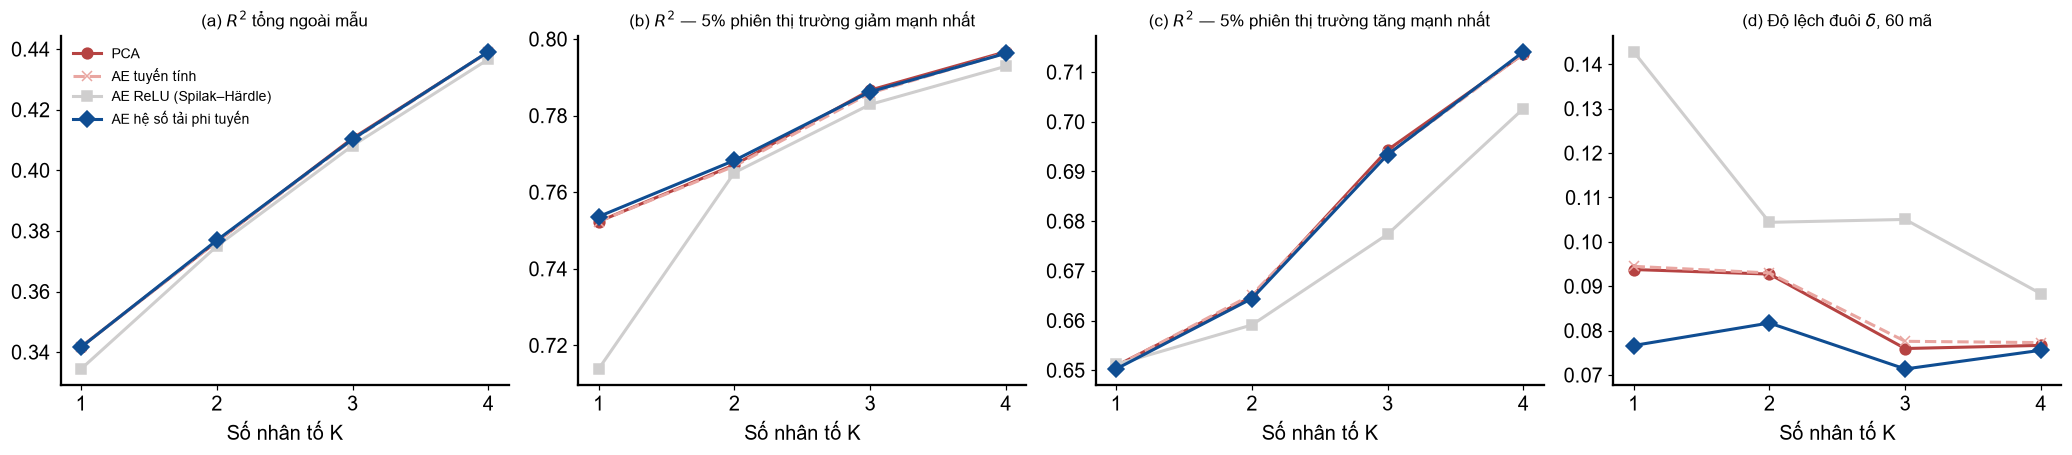

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (col, title) in zip(axes, [("R2", r"(a) $R^2$ tổng ngoài mẫu"), ("R2_duoi_duoi", r"(b) $R^2$ — 5% phiên thị trường giảm mạnh nhất"),
                                   ("R2_duoi_tren", r"(c) $R^2$ — 5% phiên thị trường tăng mạnh nhất"), ("delta_duoi_20", r"(d) Độ lệch đuôi $\delta$, 60 mã")]):
    for a in ["pca", "linear", "relu", "nonlinear"]:
        d = grid[grid.arch == a].sort_values("K")
        ax.plot(d.K, d[col], marker={"pca": "o", "linear": "x", "relu": "s", "nonlinear": "D"}[a], ms=7, lw=2,
                ls="--" if a == "linear" else "-", color=ARCH_COLORS[a], label=NF.ARCH_LABELS[a])
    ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Số nhân tố K"); ax.set_title(title, fontsize=11)
axes[0].legend(fontsize=9)
U.finalize_figure(fig, "04_real_grid", folder=FOLDER); plt.show()

### Phân tích

- **Số nhân tố:** Ahn–Horenstein chọn $K$ = 1 (nhân tố đầu chiếm 35% phương sai) — khớp Calibration 01.
- **AE tuyến tính trùng PCA** đến chữ số thứ ba ở mọi $K$ — kiểm chứng thực nghiệm Mệnh đề 1 của Gu, Kelly & Xiu (2021) và cài đặt huấn luyện.
- **AE phi tuyến hầu như không tăng $R^2$** (0,342 như PCA; đuôi dưới 0,754 so với 0,752 với $K$ = 1) — đúng kết luận của Spilak & Härdle (2022) rằng autoencoder không hơn mô hình
  tuyến tính về sai số tái tạo. Lý do: bất đối xứng chỉ đóng góp phần nhỏ vào **phương sai**, dù nó tập trung ở **đuôi**.
- **AE ReLU của Spilak & Härdle kém nhất ở đuôi dưới** ($R^2$ 0,714 so với 0,752, $\delta$ 0,143 khi $K$ = 1): vùng ReLU tắt nằm ở đuôi trái nên cú sập chung không được khử —
  đúng như chính bài báo cảnh báo (mục 4.1). Mô hình này phù hợp cho phân bổ danh mục, **không** phù hợp làm bước khử nhân tố trước phân tích đuôi.
- **Độ lệch đuôi $\delta$:** với $K$ = 1, AE phi tuyến 0,077 so với 0,094 của PCA (−18%); thấp nhất toàn lưới là AE phi tuyến $K$ = 3 (0,071). Thêm nhân tố tuyến tính giảm $\delta$ chậm hơn (PCA $K$ = 3–4: 0,076–0,077).
- Thứ tự EASE dao động mạnh theo $K$ (Spearman với $\hat\lambda$ từ 0,07 đến 0,39): thứ tự trên dữ liệu thật **không vững** với lựa chọn mô hình nhân tố — nhất quán với Validation.

## 5. Phần dư từng mã: mô hình phi tuyến sửa được gì?

**Tính gì:** so AE phi tuyến với PCA (cùng $K$ = 1, trung bình 5 seed): $\hat\Gamma^-_{m\to e_i}$, $\hat\Gamma^+_{m\to e_i}$ của từng mã theo $t(\hat D_i)$ ở mục 2.
Kỳ vọng: mã bất đối xứng mạnh ($|t| > 2$) là nơi mô hình tuyến tính để lại thành phần đồng sập/đồng tăng, và mô hình phi tuyến kéo $\hat\Gamma$ về 0,5.

δ trung bình — mã |t| > 2 (17 mã): PCA 0.116 → AE 0.084; mã còn lại: PCA 0.085 → AE 0.075
Wilcoxon một phía (δ_PCA > δ_AE, mã |t| > 2): p = 0.0033


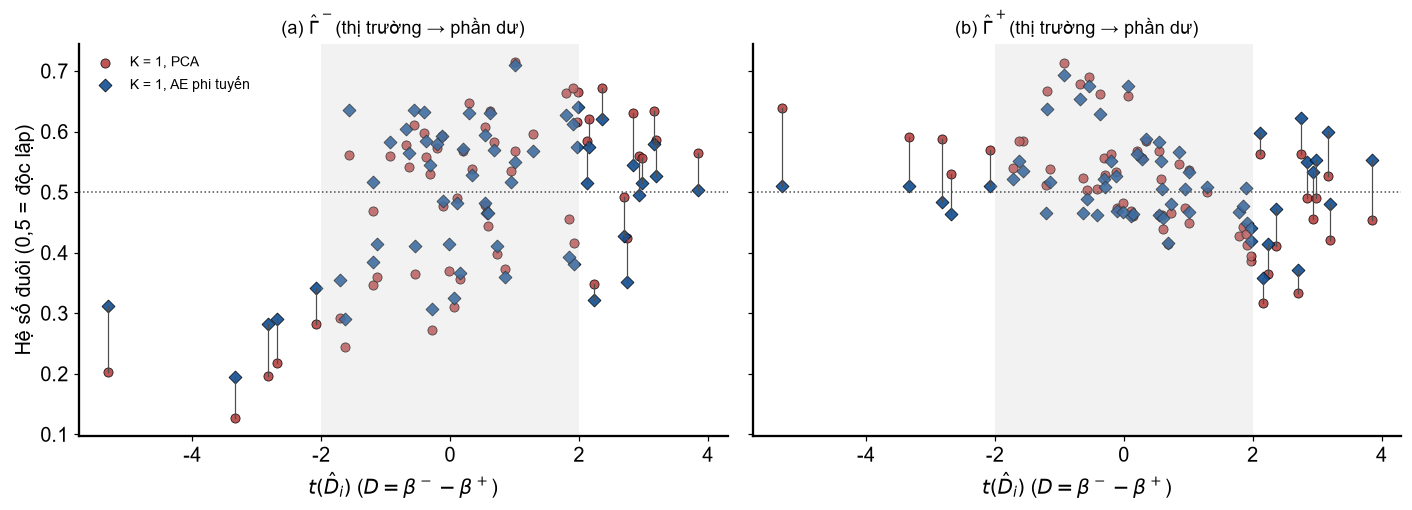

,gamma_lower|AE phi tuyến,gamma_lower|PCA,gamma_upper|AE phi tuyến,gamma_upper|PCA,t_D,dev_PCA,dev_AE
ma,,,,,,,
SSI,0.313,0.202,0.509,0.639,-5.299,0.218,0.098
DXG,0.195,0.127,0.510,0.591,-3.333,0.232,0.157
CTS,0.282,0.196,0.484,0.587,-2.824,0.196,0.117
HCM,0.290,0.218,0.464,0.531,-2.687,0.156,0.123
FTS,0.341,0.282,0.510,0.569,-2.079,0.144,0.084
HAH,0.515,0.584,0.597,0.563,2.121,0.074,0.056
GMD,0.574,0.621,0.358,0.316,2.164,0.152,0.108
PVD,0.322,0.348,0.414,0.365,2.241,0.144,0.132
HAG,0.622,0.672,0.471,0.410,2.357,0.131,0.075


In [9]:
def resid_for(a, K, seed=0):
    return NF.crossfit(Z, NF.AEConfig(K=K, arch=a, n_ensemble=5, seed=seed), n_folds=5, n_jobs=5)["resid"]

E_pca, E_nl = resid_for("pca", 1), resid_for("nonlinear", 1, seed=11)
E_nl.to_parquet(ROOT / "data" / "processed" / "ae_nonlinear_resid.parquet")
rows = []
for s in ALL:
    for lab, E in [("PCA", E_pca), ("AE phi tuyến", E_nl)]:
        e = E[s].to_numpy()
        rows.append({"ma": s, "mo_hinh": lab, "gamma_lower": CT.gamma_lower_coef(mZ, e, KC), "gamma_upper": CT.gamma_coef(mZ, e, KC)})
gm = pd.DataFrame(rows).pivot(index="ma", columns="mo_hinh").reindex(ALL)
gm.columns = [f"{a}|{b}" for a, b in gm.columns]
gm["t_D"] = ud["t_D"]
gm["dev_PCA"] = 0.5 * ((gm["gamma_lower|PCA"] - .5).abs() + (gm["gamma_upper|PCA"] - .5).abs())
gm["dev_AE"] = 0.5 * ((gm["gamma_lower|AE phi tuyến"] - .5).abs() + (gm["gamma_upper|AE phi tuyến"] - .5).abs())
U.save_table(gm, "04_residual_market_tail", FOLDER)
strong = gm["t_D"].abs() > 2
print(f"δ trung bình — mã |t| > 2 ({strong.sum()} mã): PCA {gm.loc[strong, 'dev_PCA'].mean():.3f} → AE {gm.loc[strong, 'dev_AE'].mean():.3f}; "
      f"mã còn lại: PCA {gm.loc[~strong, 'dev_PCA'].mean():.3f} → AE {gm.loc[~strong, 'dev_AE'].mean():.3f}")
w_ = stats.wilcoxon(gm.loc[strong, "dev_PCA"], gm.loc[strong, "dev_AE"], alternative="greater")
print(f"Wilcoxon một phía (δ_PCA > δ_AE, mã |t| > 2): p = {w_.pvalue:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, side, title in [(axes[0], "gamma_lower", r"(a) $\hat\Gamma^-$(thị trường → phần dư)"), (axes[1], "gamma_upper", r"(b) $\hat\Gamma^+$(thị trường → phần dư)")]:
    for lab, col, mk in [("PCA", PAL["red_strong"], "o"), ("AE phi tuyến", PAL["blue_main"], "D")]:
        ax.scatter(gm["t_D"], gm[f"{side}|{lab}"], s=36, color=col, marker=mk, edgecolor="black", lw=0.5, label=f"K = 1, {lab}", alpha=0.9)
    for s in gm.index[strong]:
        ax.plot([gm.loc[s, "t_D"]] * 2, [gm.loc[s, f"{side}|PCA"], gm.loc[s, f"{side}|AE phi tuyến"]], color=PAL["gray_dark"], lw=0.8)
    ax.axhline(0.5, color=PAL["gray_dark"], ls=":", lw=1); ax.axvspan(-2, 2, color=PAL["neutral"], alpha=0.25, lw=0)
    ax.set_xlabel(r"$t(\hat D_i)$ ($D = \beta^- - \beta^+$)"); ax.set_title(title, fontsize=12)
axes[0].set_ylabel("Hệ số đuôi (0,5 = độc lập)"); axes[0].legend(fontsize=9, loc="upper left")
U.finalize_figure(fig, "04_residual_market_tail", folder=FOLDER); plt.show()
gm.loc[strong].sort_values("t_D").round(3)

### Phân tích

- **Ở các mã bất đối xứng mạnh, AE phi tuyến làm phần dư sạch đuôi hơn rõ rệt:** $\delta$ giảm từ 0,116 xuống 0,084 (17 mã, Wilcoxon một phía $p$ = 0,003);
  ở các mã còn lại giảm ít (0,085 → 0,075).
- **Nhóm $D < 0$ (chứng khoán, DXG):** mô hình tuyến tính dự báo cú sập quá tay nên phần dư **tăng** khi thị trường sập ($\hat\Gamma^-$ chỉ 0,13–0,28) và **giảm** khi thị trường tăng
  mạnh ($\hat\Gamma^+$ 0,53–0,64); AE kéo cả hai về gần 0,5 ($\hat\Gamma^-$ 0,20–0,34, $\hat\Gamma^+$ 0,46–0,51). Ví dụ SSI: $\hat\Gamma^-$ 0,20 → 0,31, $\hat\Gamma^+$ 0,64 → 0,51.
- **Nhóm $D > 0$ (SAB, PLX, VHC, DCM, PC1…):** phần dư tuyến tính của phần lớn các mã còn **đồng sập** với thị trường ($\hat\Gamma^-$ 0,56–0,67); AE giảm còn 0,50–0,62.
- Chưa hoàn hảo: $\hat\Gamma^-$ của DXG, SSI vẫn xa 0,5, và vài mã xấu đi (HDG: $\delta$ 0,069 → 0,136; PVT 0,087 → 0,101) — một nhân tố với phần giải mã 8 nơ-ron chưa bắt hết,
  và cross-fitting chỉ có ≈ 1.700 phiên huấn luyện mỗi khối (trong đó 15% dành cho dừng sớm).

## 6. EASE sau khi khử nhân tố phi tuyến

**Tính gì:** ma trận $\hat\Psi$ ($k$ = 14) trên phần dư AE phi tuyến của 60 mã; so với PCA ngoài mẫu (cross-fitting), PCA một nhân tố trong mẫu (Kendall, Calibration 02) và hệ số có điều kiện thị trường;
trung bình trong/khác ngành; đồng thuận cặp giữa các thứ tự EASE; bootstrap khối (khối $\lceil\sqrt n\rceil$, $B$ = 200) của phần dư cho các hệ số lớn nhất và bất đối xứng
$D_{jl} = \hat\Psi_{jl} - \hat\Psi_{lj}$ (phần dư giữ cố định — khoảng chưa tính sai số ước lượng nhân tố).

In [10]:
sec = np.array([SECTOR[s] for s in SYMBOLS]); same = (sec[:, None] == sec[None, :]) & OFF
mats = {"AE phi tuyến K=1 (60 mã)": CT.tail_coef_matrix(E_nl[SYMBOLS], k=KC),
        "PCA K=1 (60 mã)": CT.tail_coef_matrix(E_pca[SYMBOLS], k=KC),
        "PCA K=1 (Kendall, trong mẫu)": C.method_matrix(Z[SYMBOLS], "pca", k=KC, K=1),
        "Có điều kiện thị trường": C.method_matrix(Z[SYMBOLS], "conditional", k=KC)}
orders = {k: CT.ease(M) for k, M in mats.items()}
real = pd.DataFrame({k: {"psi_TB": np.nanmean(M.values[OFF]), "cung_nganh": np.nanmean(M.values[same]),
                         "khac_nganh": np.nanmean(M.values[OFF & ~same]),
                         "rho_lambda": stats.spearmanr([orders[k].index(s) for s in SYMBOLS], lam20)[0],
                         "5_dau": " → ".join(orders[k][:5]), "3_cuoi": " → ".join(orders[k][-3:])} for k, M in mats.items()}).T
U.save_table(real, "04_real_ease", FOLDER)
agree = pd.DataFrame({a: {b: TP.order_agreement(orders[a], orders[b]) for b in orders} for a in orders})
display(real)
agree.round(3)

,psi_TB,cung_nganh,khac_nganh,rho_lambda,5_dau,3_cuoi
AE phi tuyến K=1 (60 mã),0.546,0.577,0.541,0.406,MSN → FRT → DGC → MWG → CTD,DCM → MBB → CTG
PCA K=1 (60 mã),0.545,0.577,0.540,0.336,MSN → HAG → FRT → DGC → MWG,BID → DPM → DCM
"PCA K=1 (Kendall, trong mẫu)",0.545,0.578,0.540,0.322,MSN → HAG → DXG → FRT → CII,CTG → DPM → DCM
Có điều kiện thị trường,0.552,0.603,0.544,0.517,SAB → FRT → TCM → VJC → HDG,VPB → SSI → HCM


,AE phi tuyến K=1 (60 mã),PCA K=1 (60 mã),"PCA K=1 (Kendall, trong mẫu)",Có điều kiện thị trường
AE phi tuyến K=1 (60 mã),1.000,0.915,0.899,0.737
PCA K=1 (60 mã),0.915,1.000,0.920,0.716
"PCA K=1 (Kendall, trong mẫu)",0.899,0.920,1.000,0.724
Có điều kiện thị trường,0.737,0.716,0.724,1.000


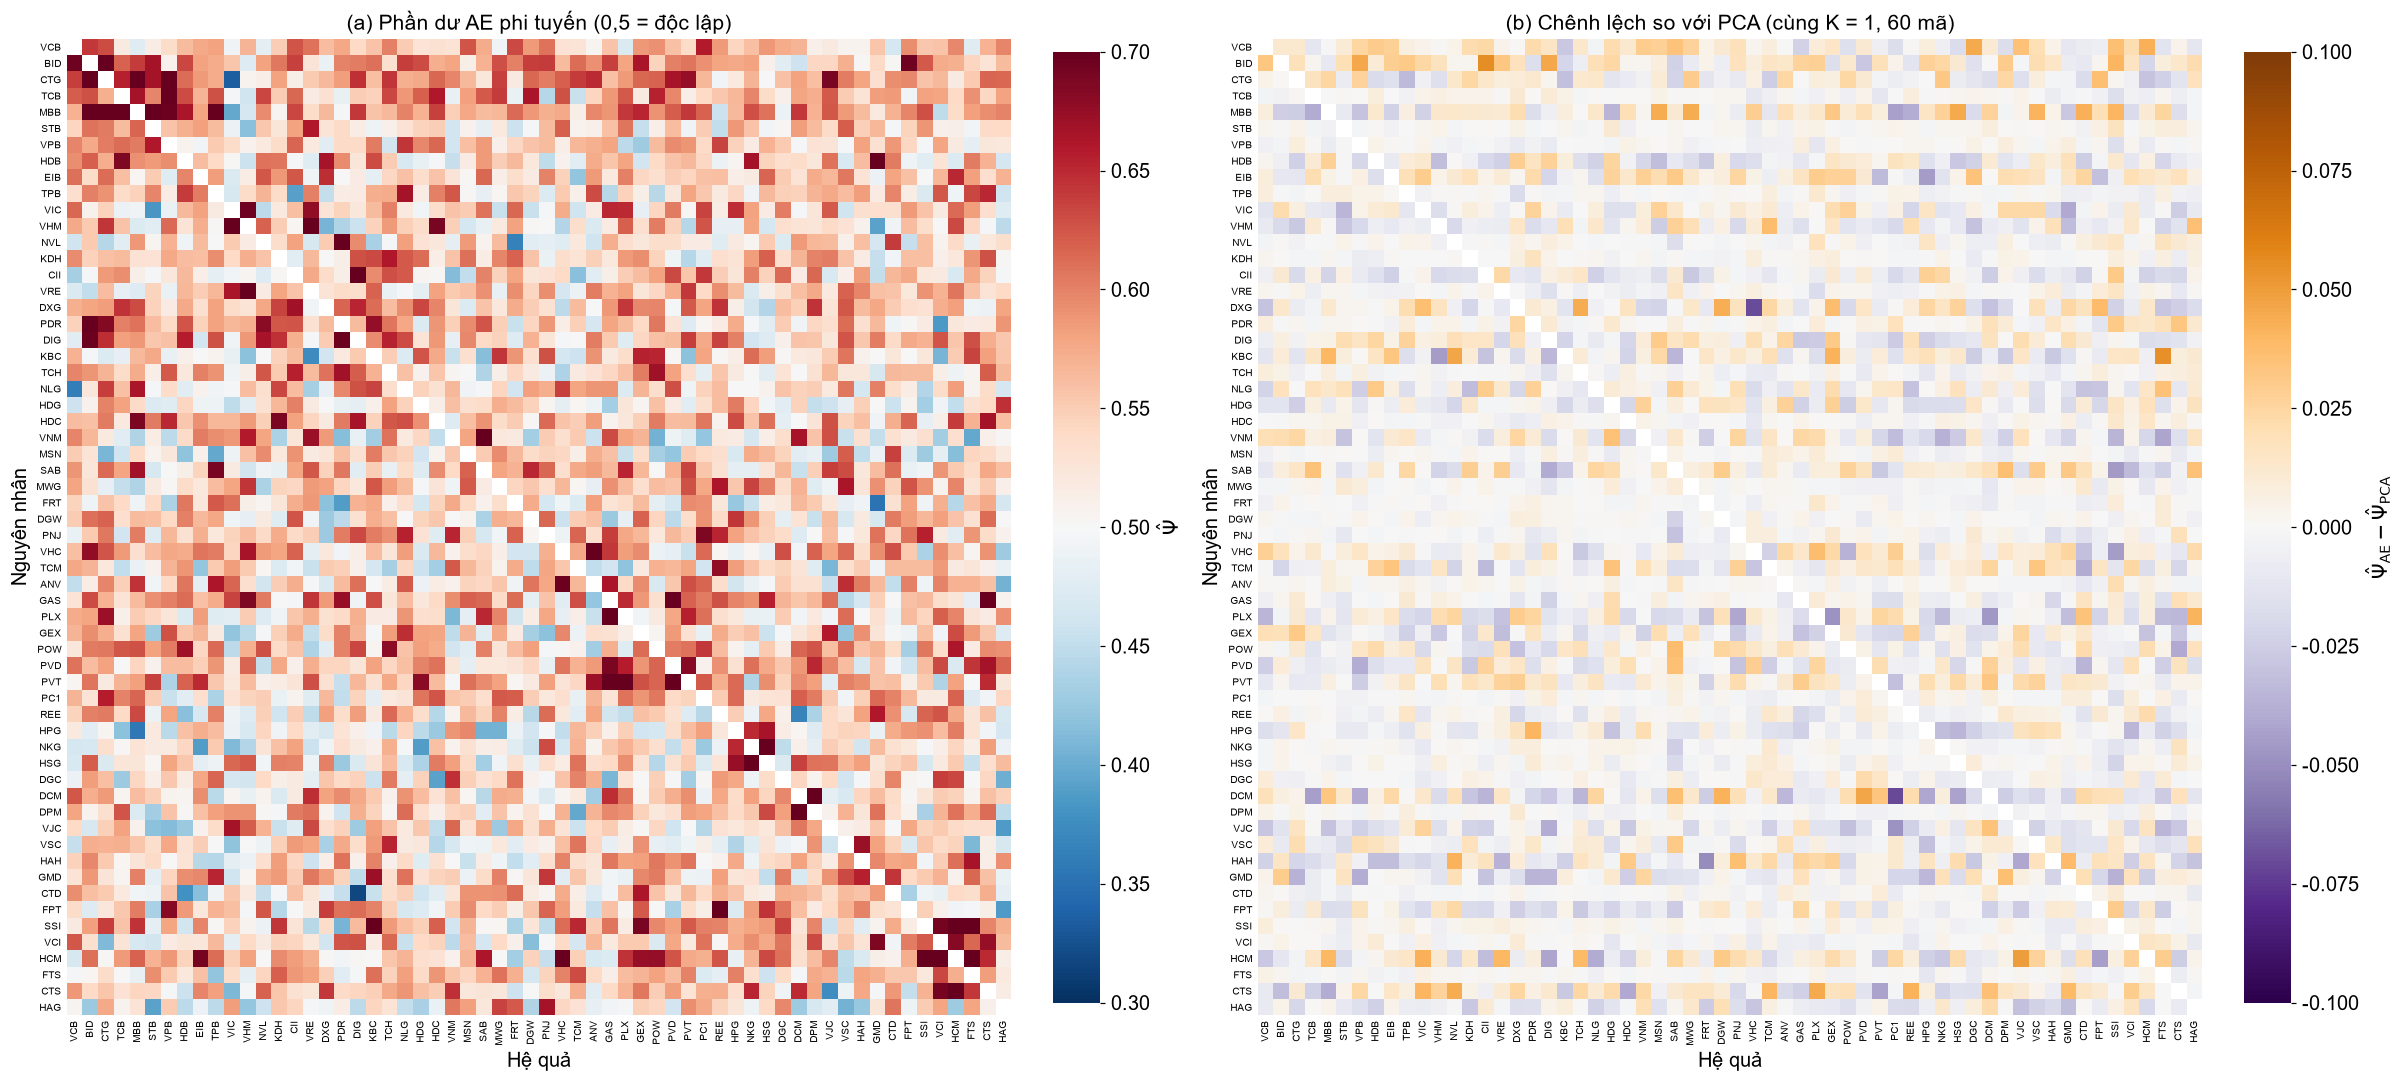

Thứ tự EASE (AE phi tuyến): MSN → FRT → DGC → MWG → CTD → HAG → PNJ → VNM → VSC → TCM → HAH → PC1 → SAB → DGW → DXG → CII → DIG → NLG → HDB → HPG → POW → TCH → NVL → PDR → HDG → PVT → PLX → GMD → KDH → GAS → PVD → CTS → GEX → VJC → HDC → EIB → FPT → REE → VCB → VHC → ANV → TPB → VRE → VHM → VIC → STB → VCI → KBC → SSI → HCM → FTS → BID → TCB → VPB → HSG → NKG → DPM → DCM → MBB → CTG


In [11]:
M_nl, M_pca = mats["AE phi tuyến K=1 (60 mã)"], mats["PCA K=1 (60 mã)"]
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
U.make_heatmap(axes[0], M_nl, cmap="RdBu_r", vmin=0.3, vmax=0.7, fmt=None, tick_fontsize=6.5, cbar_label=r"$\hat\Psi$",
               title="(a) Phần dư AE phi tuyến (0,5 = độc lập)")
U.make_heatmap(axes[1], M_nl - M_pca, cmap="PuOr_r", vmin=-0.1, vmax=0.1, fmt=None, tick_fontsize=6.5,
               cbar_label=r"$\hat\Psi_{\mathrm{AE}} - \hat\Psi_{\mathrm{PCA}}$", title="(b) Chênh lệch so với PCA (cùng K = 1, 60 mã)")
for ax in axes:
    ax.set_xlabel("Hệ quả"); ax.set_ylabel("Nguyên nhân")
U.finalize_figure(fig, "04_ease_matrix", folder=FOLDER); plt.show()
print("Thứ tự EASE (AE phi tuyến):", " → ".join(orders["AE phi tuyến K=1 (60 mã)"]))

In [12]:
E20 = E_nl[SYMBOLS]
def block_boot(b):
    rng_ = np.random.default_rng(4000 + b); L = int(np.ceil(np.sqrt(n)))
    st_ = rng_.integers(0, n - L + 1, int(np.ceil(n / L)))
    ix = (st_[:, None] + np.arange(L)).ravel()[:n]
    M = CT.tail_coef_matrix(E20.iloc[ix], k=KC, seed=b).to_numpy()
    return M, CT.ease(M)[0]
bb = Parallel(n_jobs=-1)(delayed(block_boot)(b) for b in range(200))
boot = np.array([m for m, _ in bb]); roots = pd.Series([SYMBOLS[r] for _, r in bb]).value_counts(normalize=True)
st = M_nl.stack().dropna().sort_values(ascending=False)
rows = []
for (a, b), v in st.head(12).items():
    i, j = SYMBOLS.index(a), SYMBOLS.index(b)
    dd = boot[:, i, j] - boot[:, j, i]
    rows.append({"cap": f"{a}→{b}", "nganh": f"{SECTOR[a]} → {SECTOR[b]}", "psi": v, "q05": np.quantile(boot[:, i, j], .05),
                 "q95": np.quantile(boot[:, i, j], .95), "D": v - M_nl.loc[b, a], "D_q05": np.quantile(dd, .05), "D_q95": np.quantile(dd, .95)})
top = pd.DataFrame(rows).set_index("cap"); top["co_chieu"] = (top.D_q05 > 0) | (top.D_q95 < 0)
U.save_table(top, "04_top_pairs", FOLDER)
print("Tần suất mã gốc của EASE qua bootstrap:", roots.head(5).round(2).to_dict())
top.round(3)

Tần suất mã gốc của EASE qua bootstrap: {'DGW': 0.1, 'VNM': 0.09, 'MSN': 0.08, 'HDG': 0.06, 'DGC': 0.06}


,nganh,psi,q05,q95,D,D_q05,D_q95,co_chieu
cap,,,,,,,,
DPM→DCM,Hoá chất → Hoá chất,0.813,0.737,0.891,0.041,-0.068,0.129,False
SSI→HCM,Chứng khoán → Chứng khoán,0.813,0.749,0.890,0.080,-0.045,0.214,False
HSG→NKG,Thép → Thép,0.805,0.697,0.876,0.042,-0.110,0.128,False
VHC→ANV,Tiêu dùng → Tiêu dùng,0.805,0.683,0.861,0.109,-0.026,0.197,False
MBB→CTG,Ngân hàng → Ngân hàng,0.793,0.671,0.887,0.001,-0.109,0.108,False
CTG→MBB,Ngân hàng → Ngân hàng,0.791,0.698,0.869,-0.001,-0.108,0.109,False
VRE→VHM,Bất động sản → Bất động sản,0.784,0.680,0.838,0.067,-0.069,0.140,False
VHM→VIC,Bất động sản → Bất động sản,0.783,0.679,0.851,0.089,-0.044,0.175,False
DCM→DPM,Hoá chất → Hoá chất,0.772,0.692,0.873,-0.041,-0.129,0.068,False


### Phân tích

- **Kết luận EASE không đổi về chất so với Calibration 02:** thứ tự sau khử phi tuyến đồng thuận 0,915 với PCA ngoài mẫu, 0,899 với PCA trong mẫu, 0,737 với hệ số có điều kiện.
  $\overline{\hat\Psi}$ = 0,546; cùng ngành 0,577 so với khác ngành 0,541 — **phụ thuộc đuôi còn lại trong ngành**.
- Thứ tự: MSN → FRT → DGC → MWG → CTD … → DCM → MBB → CTG. Gốc rất phân tán qua bootstrap khối (DGW 10%, VNM 9%, MSN 8%) — **không xác định được gốc**.
- Ma trận chênh lệch (b) nhỏ (|Δ| ≤ 0,07, chỉ 0,1% số ô vượt 0,05) — tác động của khử phi tuyến lên ma trận đuôi là cục bộ, ở các mã bất đối xứng (mục 2).
- **12 hệ số lớn nhất** đều trong cùng ngành hẹp: DPM↔DCM, SSI→HCM, HSG↔NKG, VHC→ANV, MBB↔CTG, VRE→VHM, VHM→VIC, TCB→VPB, MBB→TCB (0,75–0,81). Có chiều với khoảng 90% không chứa 0:
  **TCB → VPB** ($D$ = +0,16, [0,04; 0,26]) và **MBB → TCB** ($D$ = +0,08, [0,03; 0,21]) — hai gợi ý trong khối ngân hàng (MBB → TCB → VPB), khớp một phần với Calibration 02.
  Khoảng này giữ phần dư cố định và chưa hiệu chỉnh đa so sánh: vẫn là **gợi ý**, chưa phải bằng chứng.

## 7. Kết luận

1. **Dữ liệu:** 60 mã HOSE (20 mã giai đoạn trước + 40 mã chọn theo tiêu chí dữ liệu), 2.103 phiên; Ahn–Horenstein vẫn chọn một nhân tố.
2. **Phi tuyến có thật nhưng nhỏ về phương sai:** hệ số tải khi thị trường giảm khác khi tăng ở 17/60 mã, theo hai chiều (chứng khoán tăng mạnh hơn chiều lên; nhóm phòng thủ, dầu khí, cảng biển
   chủ yếu theo chiều xuống). Vì vậy AE phi tuyến **không tăng $R^2$** so với PCA — khớp Spilak & Härdle (2022) — và AE tuyến tính trùng PCA như Mệnh đề 1 của Gu, Kelly & Xiu (2021).
3. **Nhưng phần dư sạch đuôi hơn:** AE hệ số tải phi tuyến giảm độ lệch đuôi có hướng của phần dư so với thị trường 28% ở các mã bất đối xứng ($p$ = 0,003) và 18% trên toàn 60 mã.
   Trong mô phỏng, độ lệch này của PCA tăng 2,5 lần khi bất đối xứng mạnh còn của AE không đổi, SID ngang các phương pháp tốt nhất, và không mất gì khi dữ liệu tuyến tính.
   Thêm nhân tố tuyến tính thứ hai làm hỏng EASE (SID tăng ~60%). AE ReLU ràng buộc không âm của Spilak & Härdle **không** dùng được để khử nhân tố trước phân tích đuôi.
4. **Kết luận EASE giữ nguyên:** sau khử phi tuyến, phụ thuộc đuôi còn lại nằm trong các ngành hẹp, gốc EASE không xác định; gợi ý chiều MBB → TCB → VPB trong khối ngân hàng.
5. **Quy trình đề xuất:** GARCH-t → AE hệ số tải phi tuyến $K$ = 1, phần dư ngoài mẫu (cross-fitting) → EASE với $k = \lfloor n^{0{,}35}\rfloor$.
   Hướng tiếp: nhân tố ngành hẹp (chứng khoán, thép, phân bón) trong phần giải mã; đưa biến trạng thái (biến động trễ, thanh khoản) vào hệ số tải như autoencoder có điều kiện của Gu, Kelly & Xiu.